# H04. 축압기 차이는 온도 때문인가, 진짜 축압기 때문인가

| 항목 | 내용 |
|---|---|
| 질문 | 기름 온도의 영향을 빼고도 축압기 상태에 따른 압력 차이가 남을까? |
| 귀무가설 H0 | 유온(TS1_mean)을 통제하면 축압기 상태에 따른 PS1_std 차이는 없다 |
| 대립가설 H1 | 유온을 통제해도 축압기 상태에 따른 차이가 남는다 |
| 검정 | ANCOVA(공분산분석, Type II), 부분 η². 비교: 온도 통제 없는 일원 ANOVA. 가정: 잔차 정규성·등분산, 기울기 동질성 |
| 출처 (EDA) | F26 유온 × 압력 산점도, F09 |
| 데이터 | PS1_std, accumulator_bar, TS1_mean |
| 왜 중요한가 | 축압기 진단이 왜 어려운지, 온도 보정이 필요한지 |

**진행 순서:** 1 EDA 시각화 → 2 기술통계 → 3 가정 확인 → 4 정상성 확인 → 5 가설검정(p-값) → 6 사후검정·효과 크기 → 7 블록 평균 재확인 → 8 최종 판정 → 9 해석과 결정

유의수준은 **α = 0.05**로 미리 정했습니다. 표본이 2,205개로 커서 작은 차이도 p < 0.05가 되므로, **결론은 효과 크기와 함께** 내립니다.

In [1]:
from common import *
cyc = load_cycles()
print(cyc.shape)

(2205, 75)


## 1. EDA 시각화

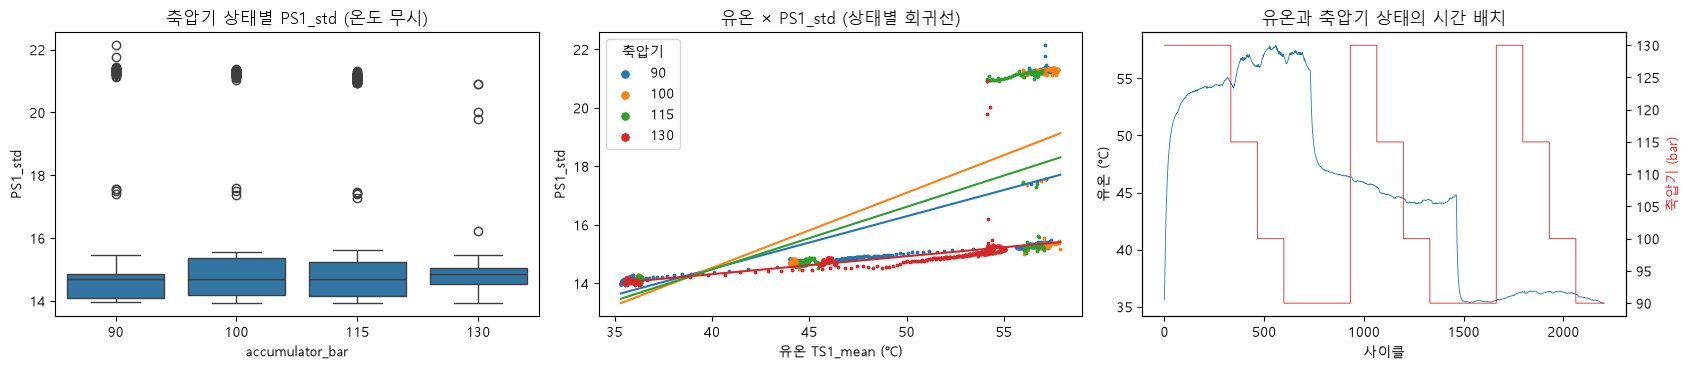

In [2]:
import statsmodels.formula.api as smf
import statsmodels.api as sm
f, c, cov = "PS1_std", "accumulator_bar", "TS1_mean"
fig, axes = plt.subplots(1, 3, figsize=(17, 3.8))
sns.boxplot(data=cyc, x=c, y=f, ax=axes[0]); axes[0].set_title("축압기 상태별 PS1_std (온도 무시)")
for v in sorted(cyc[c].unique()):
    m = cyc[c] == v; axes[1].scatter(cyc.loc[m, cov], cyc.loc[m, f], s=3, label=v)
    k, b0 = np.polyfit(cyc.loc[m, cov], cyc.loc[m, f], 1); xs = np.linspace(cyc[cov].min(), cyc[cov].max(), 10); axes[1].plot(xs, k * xs + b0)
axes[1].set_xlabel("유온 TS1_mean (°C)"); axes[1].set_ylabel(f); axes[1].legend(title="축압기", markerscale=3); axes[1].set_title("유온 × PS1_std (상태별 회귀선)")
axes[2].plot(cyc["cycle"], cyc[cov], lw=0.6); ax2 = axes[2].twinx(); ax2.step(cyc["cycle"], cyc[c], color="C3", lw=0.6, where="post")
axes[2].set_xlabel("사이클"); axes[2].set_ylabel("유온 (°C)"); ax2.set_ylabel("축압기 (bar)", color="C3"); axes[2].set_title("유온과 축압기 상태의 시간 배치")
plt.tight_layout(); plt.show()

**EDA로 본 것:** 박스플롯만 보면 차이가 작아 보입니다. 하지만 유온과 함께 보면 상태별로 선이 갈라져 있고, 유온이 PS1_std를 크게 움직입니다. 선들의 기울기가 서로 다른 점도 눈에 띕니다(→ 가정 확인).

## 2. 기술통계

In [3]:
display(cyc.groupby(c)[[f, cov]].agg(['mean', 'std']).round(2))
print('유온과 축압기 상태의 Spearman 상관:', round(stats.spearmanr(cyc[cov], cyc[c])[0], 3))

PS1_std       TS1_mean      
                   mean   std     mean   std
accumulator_bar                             
90                15.12  1.96    43.47  7.70
100               16.04  2.81    45.88  8.64
115               15.70  2.49    45.71  8.14
130               14.77  0.63    47.57  7.19

유온과 축압기 상태의 Spearman 상관: 0.218


## 3. 가정 확인

ANCOVA는 다음을 가정합니다.
1. **잔차의 정규성** (Q-Q 플롯)
2. **그룹 간 잔차 등분산** (Levene)
3. **기울기 동질성:** 유온의 영향(기울기)이 모든 축압기 상태에서 같다. 상태 × 유온 상호작용 항이 유의하지 않아야 함

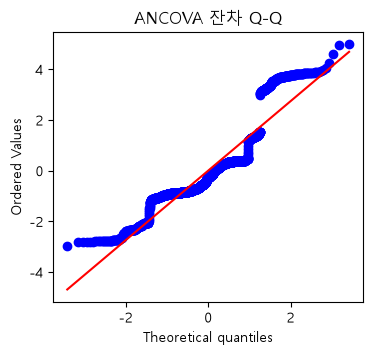

잔차 정규성 K² = 374.2, p = 5.48e-82
잔차 등분산 Levene W = 27.88, p = 1.09e-17
기울기 동질성(상호작용) F = 113.8, p = 1.74e-68 → 기울기가 상태마다 다름 (가정 위반)


In [4]:
m_anc = smf.ols(f"{f} ~ C({c}) + {cov}", data=cyc).fit()
resid = m_anc.resid
fig, ax = plt.subplots(figsize=(4, 3.5)); stats.probplot(resid, dist="norm", plot=ax); ax.set_title("ANCOVA 잔차 Q-Q"); plt.show()
k2, pn = stats.normaltest(resid); lev = stats.levene(*[resid[cyc[c] == v] for v in sorted(cyc[c].unique())], center="median")
inter = sm.stats.anova_lm(smf.ols(f"{f} ~ C({c}) * {cov}", data=cyc).fit(), typ=2).loc[f"C({c}):{cov}"]
print(f"잔차 정규성 K² = {k2:.1f}, p = {pn:.2e}")
print(f"잔차 등분산 Levene W = {lev.statistic:.2f}, p = {lev.pvalue:.2e}")
print(f"기울기 동질성(상호작용) F = {inter.F:.1f}, p = {inter['PR(>F)']:.2e} → {'기울기가 같음' if inter['PR(>F)'] >= ALPHA else '기울기가 상태마다 다름 (가정 위반)'}")

## 4. 정상성 확인

사이클 순서대로 본 이 특징이 **정상(평균·분산이 시간에 따라 일정)**인지 확인합니다. ADF(H0: 비정상)와 KPSS(H0: 정상)는 질문이 반대라서 함께 봅니다.

- 비정상이거나 자기상관이 크면 "관측값이 서로 독립"이라는 검정의 가정이 약해집니다. 그래서 7단계에서 **50사이클 블록 평균으로 다시 검정**합니다.
- KPSS p가 0.01이나 0.10으로 나오면 경계값입니다. 각각 "0.01 이하", "0.10 이상"으로 읽습니다.

- 유온이 비정상이면, 온도가 시간에 따라 흘러가면서 축압기 상태와 겹칠 수 있습니다. ANCOVA로 온도를 통제하는 이유입니다.

,특징,계열,ADF_p,KPSS_p,판정
0,PS1_std,원값,0.0206,0.010,추세·구조변화(둘 다 기각)
1,PS1_std,1차 차분,0.0000,0.100,정상
2,TS1_mean,원값,0.8718,0.010,비정상
3,TS1_mean,1차 차분,0.0000,0.023,추세·구조변화(둘 다 기각)


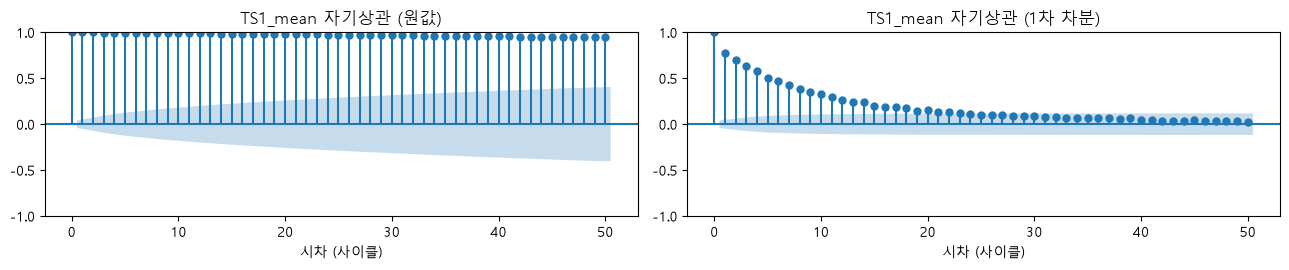

In [5]:
st = stationarity(cyc, ['PS1_std', 'TS1_mean'])
display(st.style.format({"ADF_p": "{:.4f}", "KPSS_p": "{:.3f}"}))
fig, axes = plt.subplots(1, 2, figsize=(13, 2.8))
acf_plot(cyc['TS1_mean'], "TS1_mean 자기상관 (원값)", ax=axes[0])
acf_plot(cyc['TS1_mean'].diff(), "TS1_mean 자기상관 (1차 차분)", ax=axes[1])
plt.tight_layout(); plt.show()

## 5. 가설검정 (p-값)

온도를 통제하지 않은 일원 ANOVA와, 온도를 통제한 ANCOVA를 나란히 봅니다. 부분 η² = 효과 제곱합 / (효과 제곱합 + 잔차 제곱합).

In [6]:
def effect(model, term):
    t = sm.stats.anova_lm(model, typ=2); ss, sr = t.loc[term, "sum_sq"], t.loc["Residual", "sum_sq"]
    return dict(F=t.loc[term, "F"], df1=int(t.loc[term, "df"]), df2=int(t.loc["Residual", "df"]), p=t.loc[term, "PR(>F)"], eta2p=ss / (ss + sr))
no_cov = effect(smf.ols(f"{f} ~ C({c})", data=cyc).fit(), f"C({c})")
anc = effect(m_anc, f"C({c})"); tmp = effect(m_anc, cov)
tbl = pd.DataFrame({"온도 통제 없음 (ANOVA)": no_cov, "온도 통제 (ANCOVA)": anc, "참고: 유온 자체": tmp}).T
tbl["효과"] = tbl["eta2p"].astype(float).map(lambda v: size_label(v, "eta2"))
display(tbl.style.format({"F": "{:.1f}", "p": "{:.2e}", "eta2p": "{:.3f}"}))

,F,df1,df2,p,eta2p,효과
온도 통제 없음 (ANOVA),38.5,3.000000,2201.000000,2.97e-24,0.050,작음
온도 통제 (ANCOVA),110.6,3.000000,2200.000000,1.10e-66,0.131,중간
참고: 유온 자체,1936.4,1.000000,2200.000000,6.01e-304,0.468,큼


## 6. 효과 크기 해석 + 가정 위반 대응

기울기 동질성이 깨졌으면 **축압기 상태별로 유온의 영향을 따로** 봐야 합니다. 상태별 기울기를 표로 확인합니다.

In [7]:
slopes = pd.DataFrame([dict(축압기=v, 기울기=np.polyfit(cyc.loc[cyc[c] == v, cov], cyc.loc[cyc[c] == v, f], 1)[0],
                            상관=stats.spearmanr(cyc.loc[cyc[c] == v, cov], cyc.loc[cyc[c] == v, f])[0]) for v in sorted(cyc[c].unique())])
display(slopes.round(3))
print(f"온도 통제 전 부분 η² {no_cov['eta2p']:.3f} → 통제 후 {anc['eta2p']:.3f}")

,축압기,기울기,상관
0,90,0.180,0.960
1,100,0.257,0.908
2,115,0.214,0.930
3,130,0.061,0.949


온도 통제 전 부분 η² 0.050 → 통제 후 0.131


## 7. 블록 평균으로 재확인

50사이클 블록 × 상태별로 PS1_std와 유온을 평균 낸 뒤 ANCOVA를 다시 합니다.

In [8]:
bb = cyc.assign(block=cyc["cycle"] // BLOCK).groupby(["block", c], as_index=False)[[f, cov]].mean()
banc = effect(smf.ols(f"{f} ~ C({c}) + {cov}", data=bb).fit(), f"C({c})")
print(f"블록 {len(bb)}개: F({banc['df1']}, {banc['df2']}) = {banc['F']:.1f}, p = {banc['p']:.3g}, 부분 η² = {banc['eta2p']:.3f}")

블록 56개: F(3, 51) = 3.8, p = 0.0163, 부분 η² = 0.181


## 8. 최종 판정

In [9]:
final = pd.DataFrame([dict(가설="H04", 검정="ANCOVA", 통계량=f"F({anc['df1']}, {anc['df2']}) = {anc['F']:.1f}", p=anc["p"],
    효과크기=f"부분 η² = {anc['eta2p']:.3f} (통제 전 {no_cov['eta2p']:.3f})", 블록평균_p=banc["p"],
    기울기동질성="위반" if inter["PR(>F)"] < ALPHA else "충족",
    판정="H0 기각" if (anc["p"] < ALPHA and banc["p"] < ALPHA) else "H0 유지")])
display(final)
save_result("H04", title="온도 통제 후 축압기 효과", test="ANCOVA", stat=final.통계량[0], p=anc["p"], effect=final.효과크기[0],
            verdict=final.판정[0], note="기울기 동질성 " + final.기울기동질성[0])

,가설,검정,통계량,p,효과크기,블록평균_p,기울기동질성,판정
0,H04,ANCOVA,"F(3, 2200) = 110.6",1.099386e-66,부분 η² = 0.131 (통제 전 0.050),0.016295,위반,H0 기각


저장: results/H04.json


## 9. 해석과 결정

- 온도를 통제하면 축압기 효과가 **오히려 커집니다**(부분 η² 약 0.05 → 0.13). 축압기 신호는 진짜 있고, **온도가 그것을 가리고** 있었습니다.
- 그런데 기울기 동질성이 깨졌습니다. 온도의 영향이 축압기 상태마다 다르다는 뜻이라, 온도 하나를 빼는 단순 보정으로는 부족합니다.
- **결정:** 축압기 성능이 낮은 이유(SOA: RF 0.252)를 설명하는 근거입니다. 특징 v2(4.1.1)에서 **상태별 온도 보정 또는 기준선 보정**을 검토합니다.